# Lab 1 – symulacja toru QPSK (bez płytki RFSoC)
Zamiast overlayu `rfsoc_qpsk` używamy symulatora `qpsk_sim.QpskSim` z tym samym interfejsem (`get_many_symbols`, `get_shaped_time`, `get_decimated`, `get_coarse_synced`, `get_rrced`, `get_data`, `set_gain`).
Tor: symbole QPSK → filtr RRC (8 próbek/symbol) → kanał (szum, offset częstotliwości, fazy i opóźnienie ułamkowe) → `dec` → `csync` → `rrc` → `tsync`.
Odpowiada blokom 5 i 7 laboratorium. Bloki 4 i 6 (rejestry MMIO, czas DMA) dotyczą sprzętu i nie mają sensu w symulacji.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from qpsk_sim import QpskSim, ewm

sim = QpskSim(seed=0)
tx = rx = sim

## Blok 5. Symbole i sygnał po filtrze kształtującym

symbole: (320,) complex128 | próbki w czasie: (128,) complex128


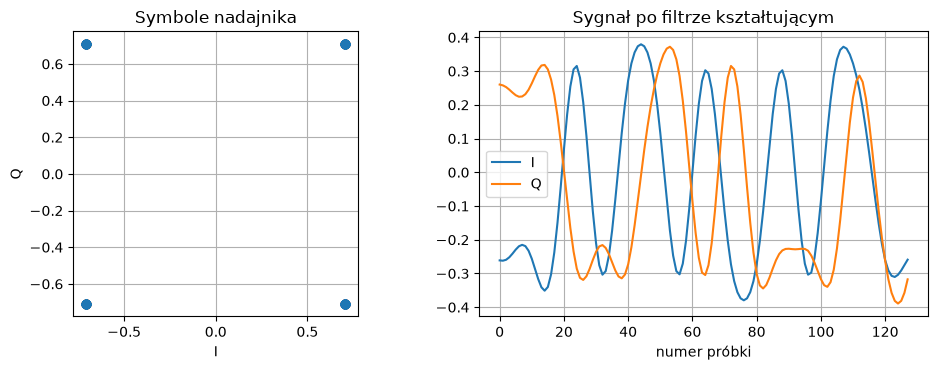

unikalne symbole: [-0.707-0.707j -0.707+0.707j  0.707-0.707j  0.707+0.707j]


In [2]:
sym  = tx.get_many_symbols(20)
czas = tx.get_shaped_time()
print("symbole:", sym.shape, sym.dtype, "| próbki w czasie:", czas.shape, czas.dtype)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(sym.real, sym.imag, "o", alpha=0.4)
ax[0].set_title("Symbole nadajnika"); ax[0].set_xlabel("I"); ax[0].set_ylabel("Q")
ax[0].set_aspect("equal"); ax[0].grid(True)
ax[1].plot(czas.real, label="I"); ax[1].plot(czas.imag, label="Q")
ax[1].set_title("Sygnał po filtrze kształtującym"); ax[1].set_xlabel("numer próbki")
ax[1].grid(True); ax[1].legend()
plt.tight_layout(); plt.show()
print("unikalne symbole:", np.round(np.unique(sym), 3))

**ZADANIE 5.1** Konstelacja ma 4 punkty: (±1 ±1j)/√2, czyli |s| = 1. Symbole są idealne, bo to wartości dyskretne z generatora. Filtr RRC rozciąga każdy symbol na kilka okresów symbolowych (inter-symbol interference jest kontrolowana, ale nie ma jej w punktach decyzyjnych), więc sygnał ciągły to suma nałożonych impulsów i wygląda zupełnie inaczej niż same symbole.

## Blok 7. Mini-projekt: analiza toru QPSK

In [3]:
N_RAMEK = 100
dane = {
    "dec":   np.concatenate([rx.get_decimated()     for _ in range(N_RAMEK)]),
    "csync": np.concatenate([rx.get_coarse_synced() for _ in range(N_RAMEK)]),
    "rrc":   np.concatenate([rx.get_rrced()         for _ in range(N_RAMEK)]),
    "tsync": np.concatenate([rx.get_data()          for _ in range(N_RAMEK)]),
}
for nazwa, v in dane.items():
    print(f"{nazwa:6s} {len(v):6d} próbek, typ {v.dtype}")

dec     51200 próbek, typ complex128
csync   51200 próbek, typ complex128
rrc     51200 próbek, typ complex128
tsync    6400 próbek, typ complex128


### 1. Cztery konstelacje

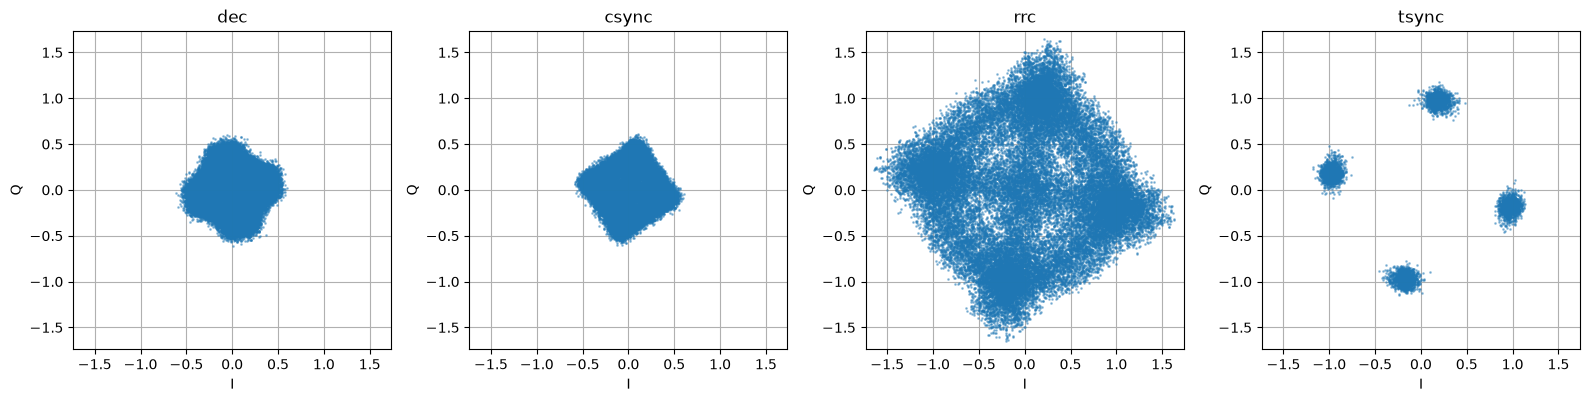

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, (nazwa, v) in zip(ax, dane.items()):
    a.plot(v.real, v.imag, ".", ms=2, alpha=0.4)
    a.set_title(nazwa); a.set_xlabel("I"); a.set_ylabel("Q")
    a.set_aspect("equal"); a.grid(True)
lim = max(np.abs(np.concatenate([v.real for v in dane.values()] + [v.imag for v in dane.values()])).max(), 1) * 1.05
for a in ax: a.set_xlim(-lim, lim); a.set_ylim(-lim, lim)
plt.tight_layout(); plt.show()

### 2. EVM po synchronizacji (`tsync`)
`ewm()` normalizuje moc, estymuje orientację konstelacji z fazy średniej `s⁴` i liczy EVM względem najbliższych punktów idealnych.

EVM (tsync) = 9.3 %


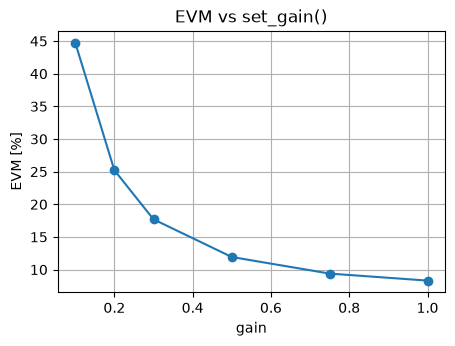

In [5]:
print(f"EVM (tsync) = {ewm(dane['tsync']):.1f} %")

# zależność EVM od wzmocnienia nadajnika (szum ADC jest stały)
gainy = [0.1, 0.2, 0.3, 0.5, 0.75, 1.0]
evm = []
for g in gainy:
    s = QpskSim(seed=1); s.set_gain(g)
    evm.append(ewm(s.tor(6400)["tsync"]))
plt.figure(figsize=(5, 3.4))
plt.plot(gainy, evm, "o-"); plt.xlabel("gain"); plt.ylabel("EVM [%]"); plt.grid(True)
plt.title("EVM vs set_gain()"); plt.show()

### 3. Widmo nadajnika i szerokość pasma −20 dB

szerokość pasma -20 dB ≈ 0.156 cykli/próbkę (teoria: (1+β)/SPS = 0.169)


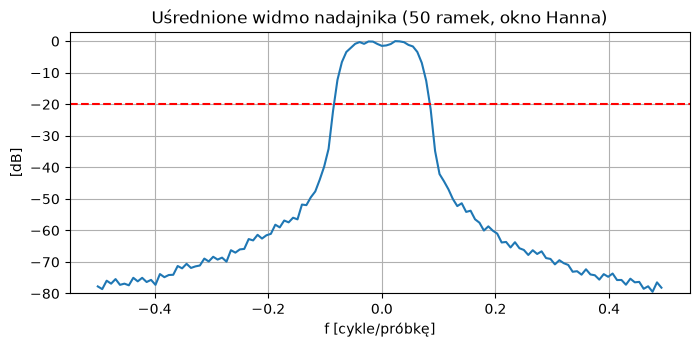

In [6]:
N = 128
okno = np.hanning(N)
P = np.zeros(N)
for _ in range(50):
    P += np.abs(np.fft.fft(tx.get_shaped_time() * okno)) ** 2
P /= 50
f = np.fft.fftshift(np.fft.fftfreq(N))            # cykle/próbkę
Pdb = 10 * np.log10(np.fft.fftshift(P) / P.max() + 1e-15)

w = f[Pdb > -20]
print(f"szerokość pasma -20 dB ≈ {w.max() - w.min():.3f} cykli/próbkę "
      f"(teoria: (1+β)/SPS = {(1 + 0.35) / 8:.3f})")
plt.figure(figsize=(8, 3.4))
plt.plot(f, Pdb); plt.axhline(-20, color="r", ls="--")
plt.xlabel("f [cykle/próbkę]"); plt.ylabel("[dB]"); plt.ylim(-80, 3); plt.grid(True)
plt.title("Uśrednione widmo nadajnika (50 ramek, okno Hanna)"); plt.show()

### 4. Wnioski
- **dec**: surowy sygnał po kanale, konstelacja to rozmyty pierścień (obrót w czasie z powodu offsetu częstotliwości, ISI od RRC).
- **csync**: po korekcji offsetu częstotliwości (pik `s⁴` w widmie) obrót ustaje; konstelacja jest nadal rozmyta, bo brak filtru dopasowanego.
- **rrc**: filtr dopasowany zwiększa SNR i skupia energię w punktach decyzyjnych, ale próbek jest wciąż 8 na symbol.
- **tsync**: wybór właściwej fazy próbkowania daje 4 skupiska; stała faza resztkowa jest usuwana przy liczeniu EVM z `s⁴`.
- **EVM vs gain**: szum ADC jest stały, więc mniejsze `gain` obniża SNR i podnosi EVM (ok. 8 % przy 1,0 do ok. 45 % przy 0,1).